In [ ]:
! pip install --upgrade seaborn matplotlib


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Path to the target folder
target_folder = "/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target3"
# Initialize list for all data
data = []
columns = ["molecule_name", "calculated_property", "reference_property", "error"]

# Loop through each model folder
for model_name in os.listdir(target_folder):
    model_path = os.path.join(target_folder, model_name)
    if not os.path.isdir(model_path):
        continue  # skip files
    csv_path = os.path.join(model_path, "results/eMBD.csv")
   
    df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
    
    # Add model info
    df["model"] = model_name
    
    data.append(df)

# Combine all model data
df_all = pd.concat(data, ignore_index=True)





/tmp/ipykernel_3524595/4133299502.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=sorted_models)


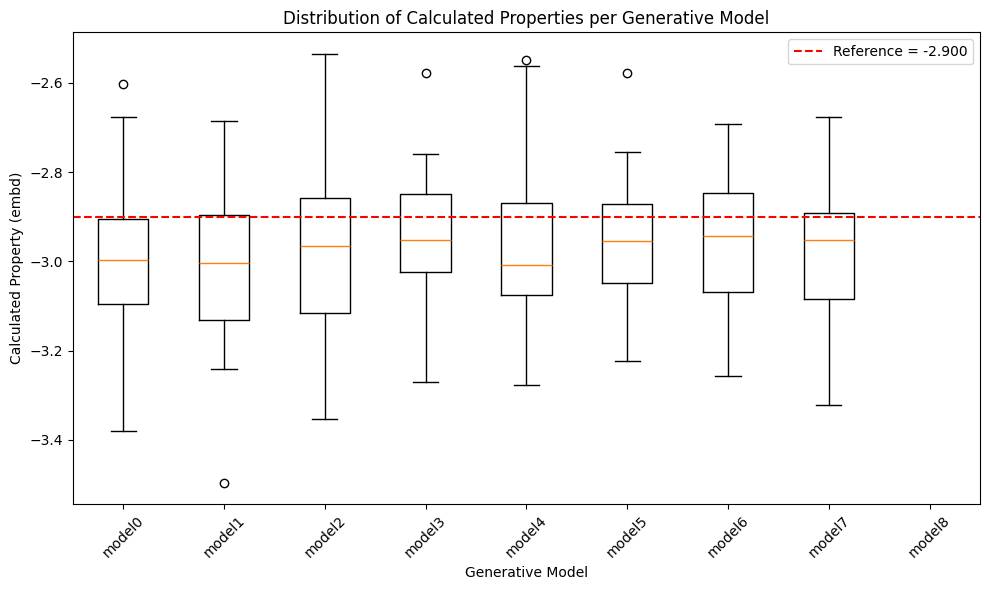

In [6]:
# Sort models alphabetically
sorted_models = sorted(df_all["model"].unique())

# Prepare data for boxplot in sorted order
box_data = [df_all[df_all["model"]==m]["calculated_property"].values for m in sorted_models]

# Plot
plt.figure(figsize=(10,6))
plt.boxplot(box_data, labels=sorted_models)
plt.xticks(rotation=45)
plt.ylabel("Calculated Property (embd)")
plt.xlabel("Generative Model")
plt.title("Distribution of Calculated Properties per Generative Model")

# Horizontal line at reference
if df_all["reference_property"].nunique() == 1:
    ref_value = df_all["reference_property"].iloc[0]
    plt.axhline(ref_value, color='red', linestyle='--', label=f"Reference = {ref_value:.3f}")
    plt.legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_3524595/3222302467.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=sorted_models)


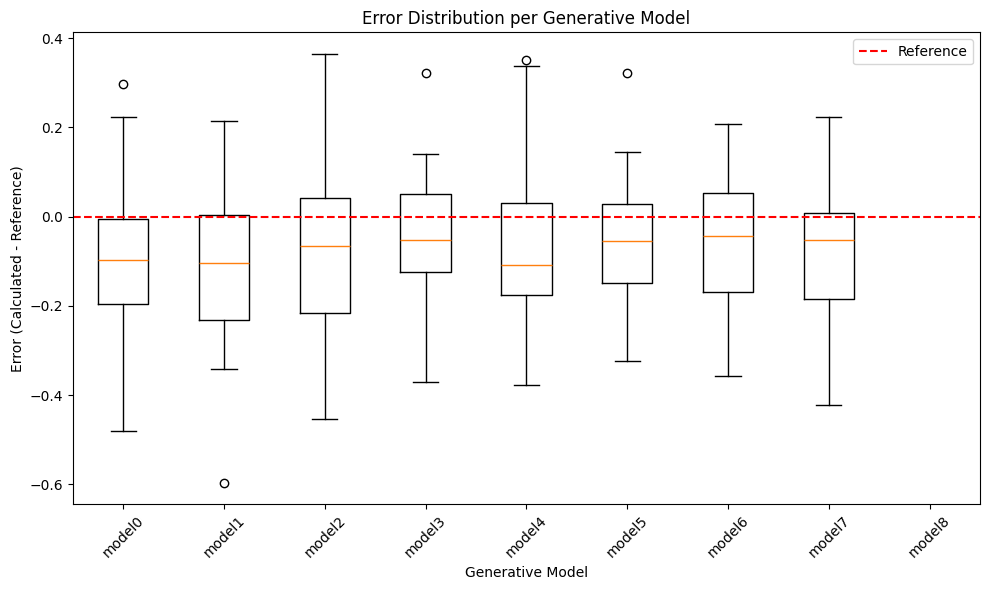

In [7]:
# Sort models alphabetically
sorted_models = sorted(df_all["model"].unique())

# Prepare data for boxplot in sorted order
box_data = [df_all[df_all["model"]==m]["error"].values for m in sorted_models]

# Plot
plt.figure(figsize=(10,6))
plt.boxplot(box_data, labels=sorted_models)
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model")

# Horizontal reference line at zero
plt.axhline(0, color='red', linestyle='--', label="Reference")
plt.legend()
plt.tight_layout()
plt.show()


/tmp/ipykernel_617929/3251561500.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile")


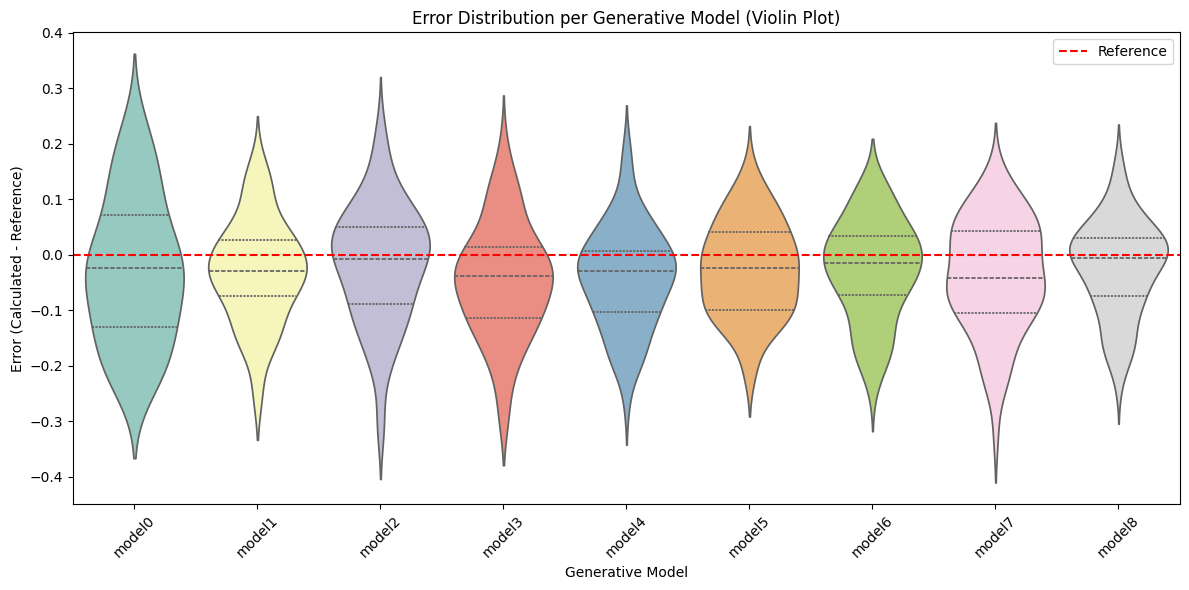

In [16]:
# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot of errors
plt.figure(figsize=(12,6))
sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile")

# Horizontal line at 0 (reference)
plt.axhline(0, color='red', linestyle='--', label="Reference")

plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model (Violin Plot)")
plt.legend()
plt.tight_layout()
plt.show()

## Two Targets

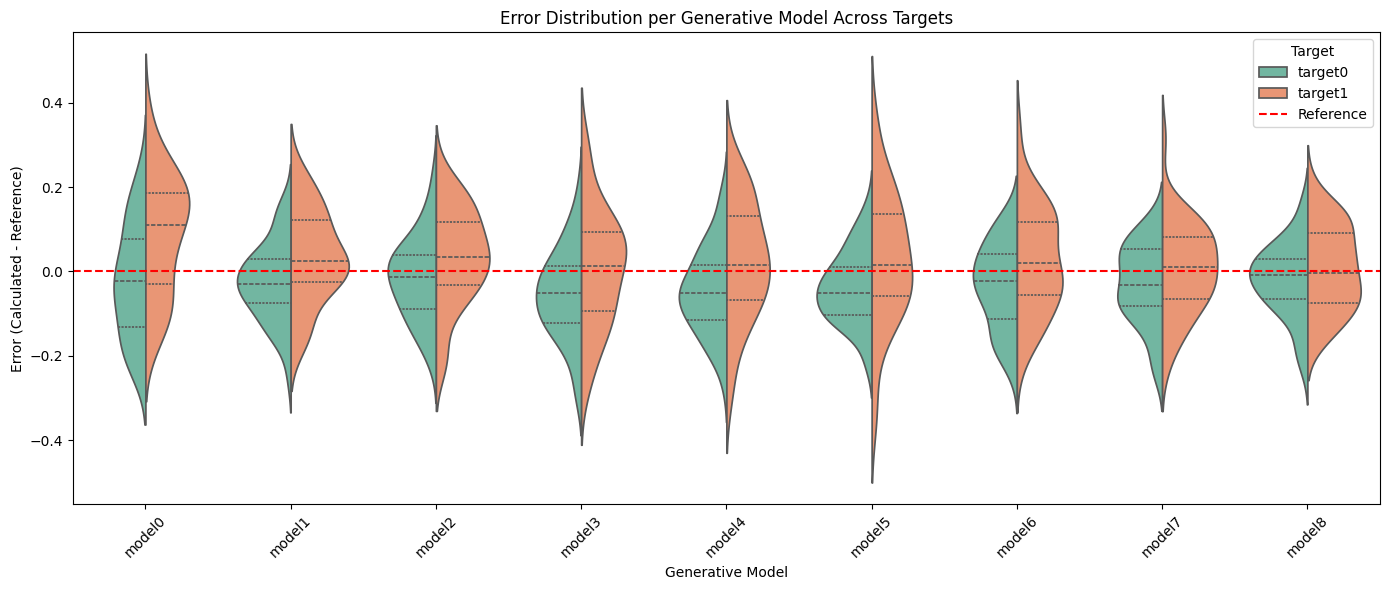

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# List of target folders
target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target0"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target1")
]

columns = ["molecule_name", "calculated_property", "reference_property", "error"]
data = []

for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        
        # Add model and target info
        df["model"] = model_name
        df["target"] = target_name
        
        # Calculate error if missing
        if "error" not in df.columns or df["error"].isnull().all():
            df["error"] = df["calculated_property"] - df["reference_property"]
        # Subsample max 40 molecules per model
        if len(df) > 40:
            df = df.sample(n=40, random_state=42)
            
        data.append(df)

# Combine all data
df_all = pd.concat(data, ignore_index=True)

# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="error", hue="target", palette="Set2", split=True, inner="quartile")

# Horizontal reference line at 0
plt.axhline(0, color='red', linestyle='--', label='Reference')

plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across Targets")
plt.legend(title="Target")
plt.tight_layout()
plt.show()


## All Targets

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# List of target folders and their names
target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target0"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target1"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target2"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target3")
]

columns = ["molecule_name", "calculated_property", "reference_property", "error"]
data = []

for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        df["model"] = model_name
        df["target"] = target_name
        
        if "error" not in df.columns or df["error"].isnull().all():
            df["error"] = df["calculated_property"] - df["reference_property"]
        
        # Subsample max 40 molecules per model
        if len(df) > 40:
            df = df.sample(n=40, random_state=42)
            
        data.append(df)

df_all = pd.concat(data, ignore_index=True)

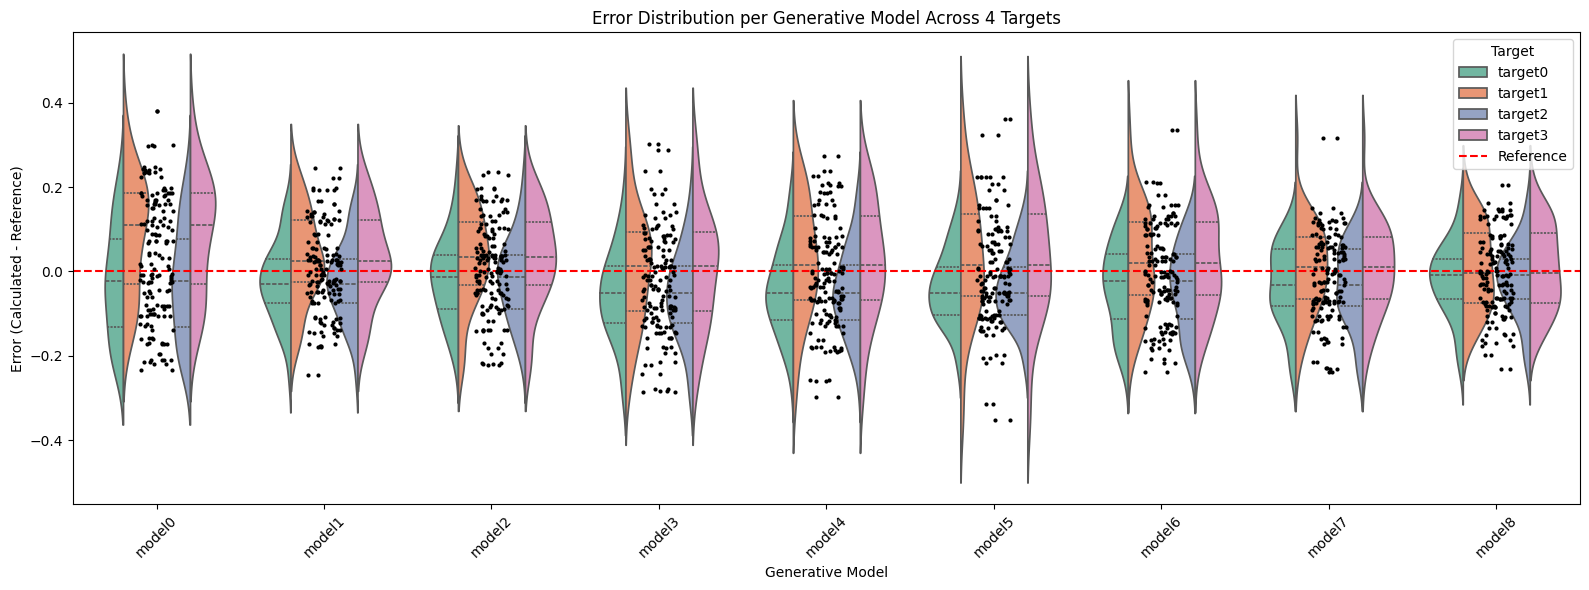

In [33]:
# Alphabetically sort models
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot, side-by-side violins for each target
plt.figure(figsize=(16,6))
sns.violinplot(data=df_all, x="model", y="error", hue="target", palette="Set2", split=True, inner="quartile")
sns.stripplot(data=df_all, x="model", y="error", color='black', size=3, jitter=True)

plt.axhline(0, color='red', linestyle='--', label='Reference')
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across 4 Targets")
plt.legend(title="Target")
plt.tight_layout()
plt.show()


/tmp/ipykernel_617929/3582815188.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')
/tmp/ipykernel_617929/3582815188.py:6: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')


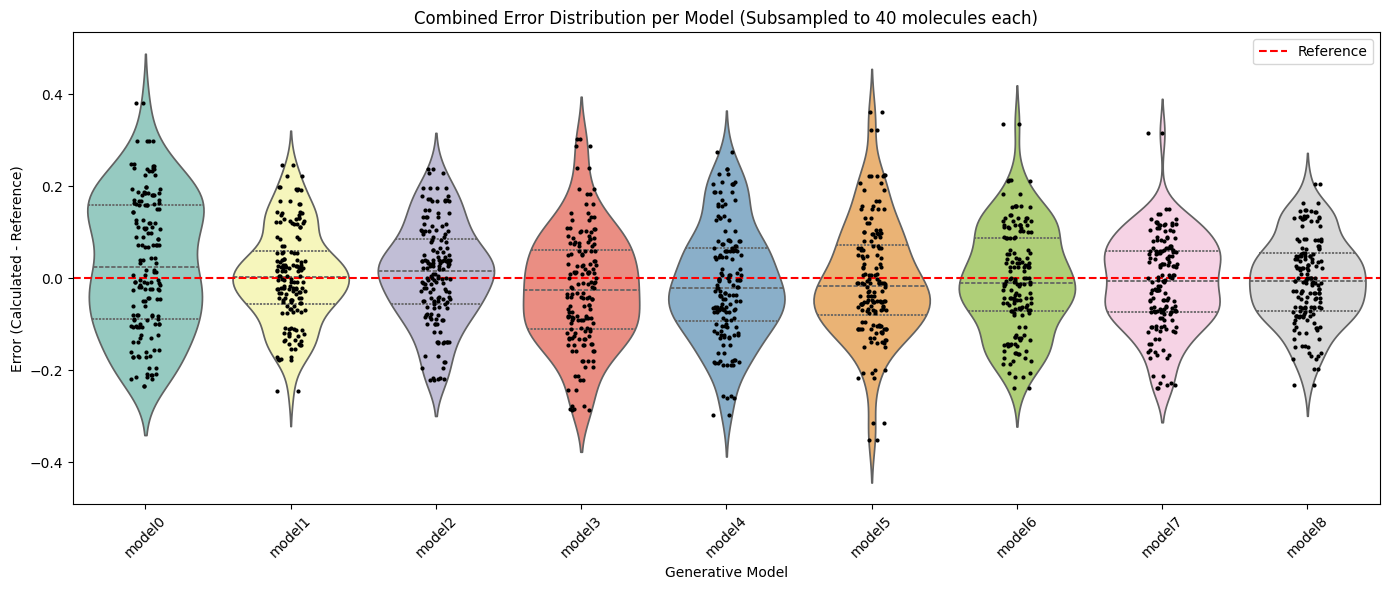

In [34]:
# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')

# Optional: overlay individual points
sns.stripplot(data=df_all, x="model", y="error", color='black', size=3, jitter=True)

plt.axhline(0, color='red', linestyle='--', label='Reference')
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Combined Error Distribution per Model (Subsampled to 40 molecules each)")
plt.legend()
plt.tight_layout()
plt.show()


## Final

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# List of target folders and their names
target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target0"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target1"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target2", "target2"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target3", "target3")
]
columns = ["molecule_name", "calculated_property", "reference_property", "error"]
data = []

# Read all targets
for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        df["model"] = model_name
        df["target"] = target_name
        
        # Calculate relative error
        df["relative_error"] = (df["calculated_property"] - df["reference_property"]) / df["reference_property"]
        
        # Subsample max 40 molecules per model
        if len(df) > 40:
            df = df.sample(n=40, random_state=42)
        
        data.append(df)

# Combine all data
df_all = pd.concat(data, ignore_index=True)

# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)



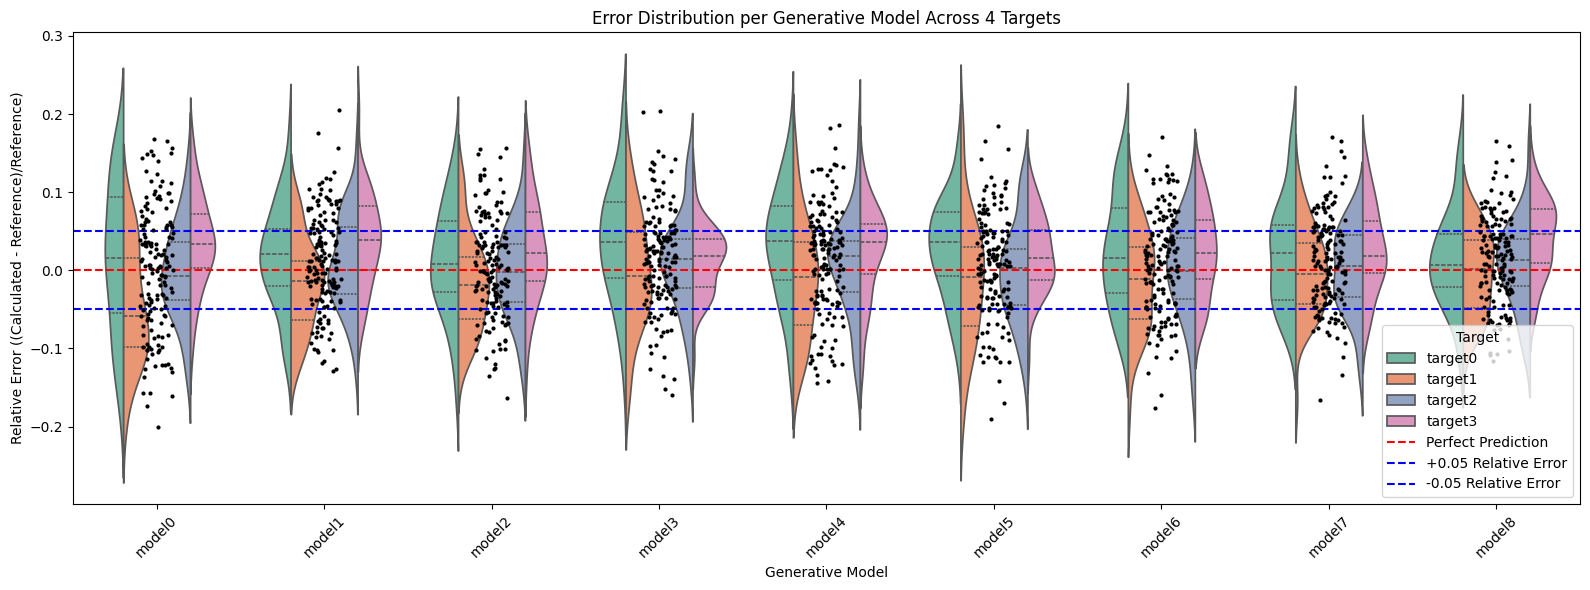

In [2]:
# Plot violin plot, side-by-side violins for each target
plt.figure(figsize=(16,6))
sns.violinplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", split=True, inner="quartile")
sns.stripplot(data=df_all, x="model", y="relative_error", color='black', size=3, jitter=True)

# Horizontal lines: perfect prediction, ±0.5 relative error
plt.axhline(0, color='red', linestyle='--', label='Perfect Prediction')
plt.axhline(0.05, color='blue', linestyle='--', label='+0.05 Relative Error')
plt.axhline(-0.05, color='blue', linestyle='--', label='-0.05 Relative Error')

plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across 4 Targets")
plt.legend(title="Target")
plt.tight_layout()
plt.show()

/tmp/ipykernel_3524595/2205483133.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')
/tmp/ipykernel_3524595/2205483133.py:3: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')


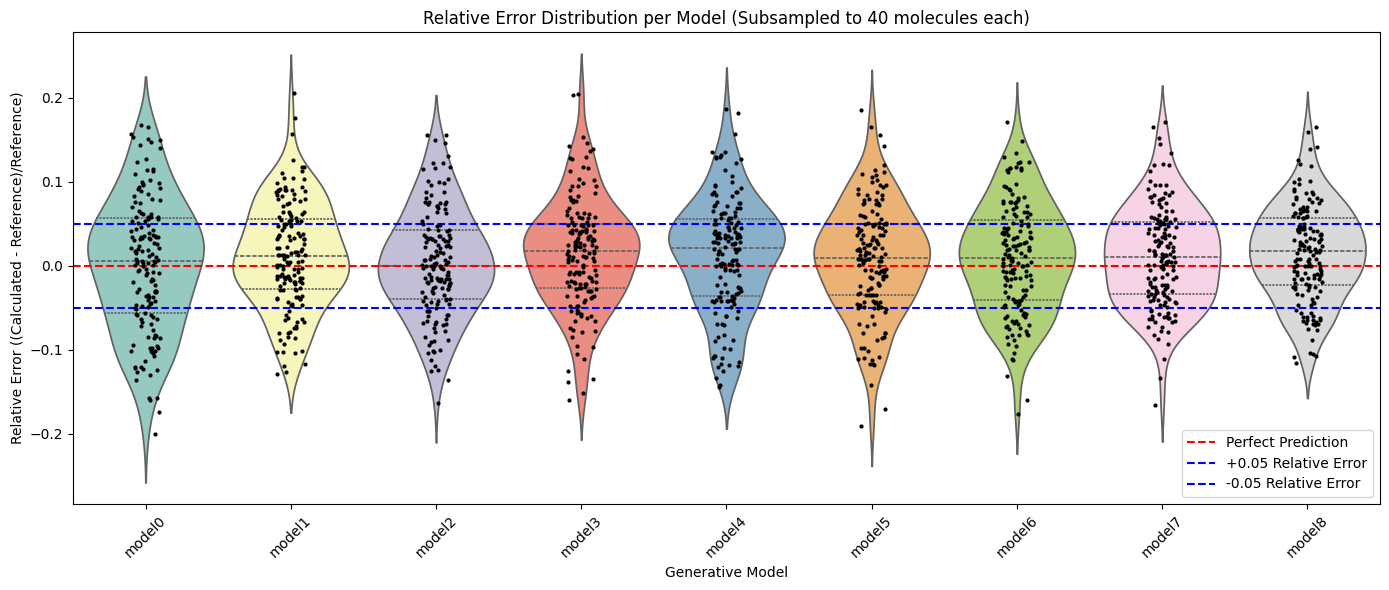

In [3]:
# Plot violin plot of relative errors
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')

# Overlay individual points
sns.stripplot(data=df_all, x="model", y="relative_error", color='black', size=3, jitter=True)

# Horizontal lines: perfect prediction, ±0.5 relative error
plt.axhline(0, color='red', linestyle='--', label='Perfect Prediction')
plt.axhline(0.05, color='blue', linestyle='--', label='+0.05 Relative Error')
plt.axhline(-0.05, color='blue', linestyle='--', label='-0.05 Relative Error')

plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Relative Error Distribution per Model (Subsampled to 40 molecules each)")
plt.legend()
plt.tight_layout()
plt.show()


Stable spread across models:
The shape and width of the violins remain relatively constant across model0 → model8.
→ The predictive precision and consistency are being maintained throughout training iterations — later models do not “explode” or degrade in quality.

Slight tightening trend:
If you look closely, the violins from model0 to around model7 appear marginally narrower and more concentrated near zero.
→ That could indicate a small improvement in stability or uncertainty reduction over the loop — consistent with an active learning setup refining its model confidence.

Over successive generative models, the relative error distributions for predicted Eₘᴮᴰ values remain centered and compact.
The active learning process seems to have stabilized prediction quality across iterations, with only a minor upward drift in the central tendency.
In other words, your generative models are learning in a steady, robust manner without diverging — a good sign of convergence and reliability in the feedback loop.

In [ ]:
! pip install scipy

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

# df_all is your combined dataframe with columns: model, relative_error
# If not already computed:
# df_all["relative_error"] = (df_all["calculated_property"] - df_all["reference_property"]) / df_all["reference_property"]

# optionally clip extreme relative errors for stable stats
df_all = df_all.copy()
# if you want to cap e.g. to [-2, 2] to reduce influence of huge outliers:
df_all['relative_error_clipped'] = df_all['relative_error'].clip(-2, 2)

# 1) per-model summary stats
def mad(series):
    return (series - series.median()).abs().median()

grouped = df_all.groupby('model')['relative_error_clipped']
summary = grouped.agg(
    count='count',
    median='median',
    mean='mean',
    std='std',
    mad=lambda x: mad(x),
    pct_within_0_05=lambda x: (x.abs() <= 0.05).mean() * 100,
    pct_within_0_1 = lambda x: (x.abs() <= 0.1).mean() * 100
).sort_index()

# Show summary
pd.options.display.float_format = '{:.4f}'.format
print(summary)

# # 2) bar plots: median and percent within ±0.05
# fig, axs = plt.subplots(1,2, figsize=(14,5))
# summary['median'].plot.bar(ax=axs[0])
# axs[0].axhline(0, color='red', linestyle='--')
# axs[0].set_title('Median relative error per model')
# axs[0].set_ylabel('Median relative error')

# summary['pct_within_0_05'].plot.bar(ax=axs[1], color='C1')
# axs[1].set_title('% of samples with |relative error| <= 0.05')
# axs[1].set_ylabel('Percent (%)')

# plt.tight_layout()
# plt.show()

# # 3) If model names have numeric order (model0, model1, ...), try extracting index for trend analysis.
# def extract_index(name):
#     m = re.search(r'(\d+)', name)
#     return int(m.group(1)) if m else None

# model_index = pd.Series({m: extract_index(m) for m in summary.index})
# if model_index.isnull().any():
#     # fallback: use enumeration order (sorted names)
#     model_index = pd.Series({m: i for i,m in enumerate(sorted(summary.index))})

# # create series aligned by model name
# median_series = summary['median']
# index_series = model_index.loc[median_series.index].astype(float)

# # Spearman-like check using pandas corr (rank-based)
# spearman_corr = median_series.corr(index_series, method='spearman')
# pearson_corr = median_series.corr(index_series, method='pearson')
# print(f"Spearman corr (median vs model index): {spearman_corr:.4f}")
# print(f"Pearson corr (median vs model index): {pearson_corr:.4f}")

# # Also check proportion within threshold vs index:
# pct_series = summary['pct_within_0_05']
# print("Correlation (pct within 0.05 vs index):",
#       pct_series.corr(index_series, method='spearman'))


        count  median   mean    std    mad  pct_within_0_05  pct_within_0_1
model                                                                      
model0    160  0.0058 0.0010 0.0794 0.0528          45.0000         77.5000
model1    160  0.0113 0.0118 0.0633 0.0422          56.2500         88.1250
model2    157  0.0001 0.0033 0.0646 0.0414          57.9618         85.9873
model3    160  0.0174 0.0146 0.0657 0.0396          60.0000         86.2500
model4    160  0.0215 0.0125 0.0687 0.0457          55.6250         83.7500
model5    160  0.0093 0.0067 0.0663 0.0424          58.7500         86.2500
model6    160  0.0096 0.0091 0.0654 0.0487          54.3750         87.5000
model7    160  0.0109 0.0112 0.0599 0.0421          57.5000         91.8750
model8    158  0.0174 0.0147 0.0570 0.0399          58.1250         90.0000


/tmp/ipykernel_3524595/4141423639.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df_all.groupby('model')['relative_error_clipped']


Across the 8 active-loop generative models, the relative error distributions remain tight and mostly unbiased.
There’s a small upward drift in the median error (from ≈0.006 to ≈0.017), suggesting that the models slightly overpredict the Eₘᴮᴰ values as the loop progresses.
However, the overall proportion of accurate predictions (within ±5%) improves slightly, indicating stable or improving reliability.
This could reflect a shift in the generated molecule space toward higher-energy compounds, consistent with an active learning bias toward “interesting” regions.